# Лабораторна 5. Донавчання моделей (Fine-Tuning)

**Тема**: Донавчання LLM складати ірландські мелодії в нотації ABC

**Вид донавчання:** SFT - контрольоване донавчання на парах «запит → еталонна відповідь» **з LoRA**.

**Моделі:** `Qwen3-0.6B` і `Qwen3-1.7B`.

**Дані:** [IrishMAN](https://huggingface.co/datasets/sander-wood/irishman), 216 тис. ірландських мелодій у нотації ABC.

**Ідея.** Користувач задає параметри мелодії, модель повертає **готову мелодію в ABC**. На відміну від більшості задач із текстом, результат можна **перевірити програмою**: парсер `abc2midi` каже, чи є в ABC синтаксичні помилки і чи кожен такт має правильну тривалість для заданого розміру. Це дає об'єктивні метрики без «LLM-судді».

| Розділ | Зміст |
|---|---|
| 1.1 | Задача й чому для неї потрібне донавчання |
| 1.2 | Моделі, вид донавчання, дані, поділ без витоку |
| 1.3 | Метрики й результат **до** донавчання |
| 1.4 | SFT + LoRA: гіперпараметри, криві loss, час і памʼять; абляція рангу LoRA |
| 1.5 | Порівняння до/після, аналіз помилок, перевірка загальних здібностей, прослуховування |
| 1.6 | Звіт |

In [1]:
# trl — SFT, peft — LoRA. abcmidi — парсер ABC, яким перевірятимемо згенеровані мелодії
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate"
!pip uninstall -q -y torchao
!apt-get -qq install -y abcmidi > /dev/null

In [2]:
import gc
import math
import os
import random
import re
import shutil
import subprocess
import tempfile
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import Audio, Markdown, display
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

assert torch.cuda.is_available(), "Потрібна GPU: Runtime → Change runtime type → T4 GPU"
assert shutil.which("abc2midi"), "abc2midi не встановлено: виконайте клітинку з apt-get install abcmidi"
print(f"GPU: {torch.cuda.get_device_name()}, памʼять: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

SEED = 42
set_seed(SEED)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

QUICK = False               # True — швидкий прогін для перевірки коду
RUN_RANK_ABLATION = True    # абляція рангу LoRA на Qwen3-0.6B
LISTEN = True               # синтезувати й прослухати кілька мелодій

CFG = dict(
    n_pool=60_000,      # скільки випадкових мелодій IrishMAN беремо в обробку
    n_train=4_000,      # максимум тренувальних прикладів - за 300 кроків × 8 бачимо ≈ 2400
    n_val=150,          # для validation loss під час тренування
    n_test=200,         # тестові запити; на кожен генеруємо по одній мелодії
    max_steps=300,
    eval_steps=25,
)
if QUICK:
    CFG.update(n_pool=3_000, n_train=600, n_val=24, n_test=24, max_steps=20, eval_steps=10)
    RUN_RANK_ABLATION = False
print(CFG)

MAX_ANSWER_TOKENS = 380     # довші мелодії відкидаємо: вони не вміщуються в T4 разом із промптом
MAX_NEW_TOKENS = 450        # ліміт генерації


def free_memory():
    """Звільняє памʼять GPU після видалення моделей."""
    gc.collect()
    torch.cuda.empty_cache()

GPU: Tesla T4, памʼять: 15.6 GB
{'n_pool': 60000, 'n_train': 4000, 'n_val': 150, 'n_test': 200, 'max_steps': 300, 'eval_steps': 25}


## 1.1. Задача

**Сценарій.** Музикант хоче швидко отримувати чернетки мелодій у вигляді, який можна одразу відкрити в редакторі нот чи програти.

| | |
|---|---|
| **Користувач** | музикант, автор ігор, викладач, що готує вправи |
| **Вхід** | 4 параметри: розмір, тональність, одиниця тривалості нот, кількість тактів |
| **Вихід** | одна мелодія в нотації ABC, яку приймає ABC-парсер і де кожен такт має довжину, що відповідає розміру |

**Що таке ABC.** Це текстовий запис нот. Приклад мелодії на 2 такти у розмірі 6/8:

```
X:1
L:1/8
M:6/8
K:D
d2 d ded | cBA ABc |
```

Рядки `L`, `M`, `K` задають одиницю тривалості, розмір і тональність; літери це ноти, цифри це множники тривалості, `|` це тактові риски.
Головна складність для мовної моделі в тому, що це **не просто текст**: синтаксис суворий, а кожен такт має мати **точну суму тривалостей**.

**Чому донавчання, а не промпт чи RAG.**

* **RAG не підходить:** пошук готових мелодій дав би копіювання, а не створення нової мелодії за параметрами.
* **Промпт** може пояснити ABC, але: довгий промпт з поясненням і прикладом оплачується на *кожному* запиті; арифметика тривалостей у тактах і підрахунок кількості тактів для малих LLM складні, і довге пояснення цього не вирішує; мала модель із поясненням ABC ймовірно плутає синтаксис.
* **Донавчання** закріплює формат і знання про тривалості у вагах. Після нього короткий промпт має давати валідні мелодії.

**Гіпотези:**

1. З довгим промптом без донавчання невелика модель дає повністю валідні мелодії **рідко**; після SFT частка валідних зростає в рази.
2. Виконати *числові* обмеження важче, ніж просто писати синтаксично коректний ABC: ця метрика зросте менше.
3. Більша модель краща за меншу, але після донавчання розрив скоротиться.
4. LoRA майже не псує загальних здібностей моделі.

## 1.2. Моделі, вид донавчання, дані

### Вид донавчання: SFT + LoRA

Ці два терміни відповідають на різні питання:

* **Що тренуємо?** Це **SFT**, контрольоване донавчання: модель вчиться на парах «запит → еталонна відповідь».
* **Як тренуємо?** Методом **LoRA**: ваги базової моделі заморожені, додаємо малі низькорангові матриці до всіх лінійних шарів. Це знижує памʼять і дозволяє на T4 тренувати моделі до ~4 млрд параметрів. У `loss` рахуємо **лише токени відповіді** за допомогою параметра `assistant_only_loss=True`.

### Моделі

| Модель | Параметри | Навіщо |
|---|---|---|
| `Qwen/Qwen3-0.6B` | 0,6 млрд | швидка, показує, чи може *мала* модель після донавчання стати придатною |
| `Qwen/Qwen3-1.7B` | 1,7 млрд | основна: компроміс якості й часу |

* **Instruct:** потрібен чат-шаблон, щоб однаково будувати запит у «до» і «після», і щоб перевірити загальні здібності. Base-модель вимагала б власного формату.
* **Чому не більша:** потрібно 4 тренування й 6–8 прогонів генерації; 4B не вкладається в розумний час на T4.
* **Чому не готова музична модель**: наприклад TunesFormer натренована саме на цьому датасеті але ми адаптуємо *універсальну* LLM до нової задачі. Ну і для виконання лабораторної не цікаво використовувати готові моделі.

### Дані: IrishMAN

[`sander-wood/irishman`](https://huggingface.co/datasets/sander-wood/irishman): 216 284 ірландські мелодії в ABC зі збірок thesession.org та abcnotation.com. Мелодії у public domain; за карткою датасету він **призначений лише для дослідницького використання**, ліцензія в метаданих MIT.

**Застереження, які ми врахуємо:**

* У традиційній музиці одна й та сама мелодія зустрічається в десятках **варіантів**. Випадковий поділ train/test дав би витік. Тому поруч з дедуплікацією ми викидаємо з train усе, що схоже на тест чи validation.
* Частина мелодій парсер `abc2midi` вважає хибними або з нерівними тактами. Вчити модель на них неправильно, тому тренуємо лише на мелодіях, що проходять перевірку.
* Модель може просто **запамʼятати** тренувальні мелодії; вимірюємо частку дослівних копій.

### Допоміжні функції для ABC

Розбираємо мелодію на заголовок і тіло, перетворюємо тональність на людську назву, рахуємо такти й будуємо з кожної мелодії **запит** та **еталон**. Кількість тактів ми рахуємо власною функцією однаково й для еталонів, і для відповідей моделі, тож порівняння чесне.

In [4]:
HEADER_RE = re.compile(r"^([A-Za-z]):\s*(.*)$")
BARLINE_RE = re.compile(r"\|\]|\[\||\|\||::|:\||\|:|\|")
MODES = {"": "major", "maj": "major", "ion": "major", "m": "minor", "min": "minor", "aeo": "minor",
         "dor": "dorian", "mix": "mixolydian", "lyd": "lydian", "phr": "phrygian", "loc": "locrian"}


def split_abc(abc):
    """Повертає заголовки-словник, текст тіла. Заголовок закінчується рядком K:."""
    lines = abc.replace("\r\n", "\n").replace("\r", "\n").strip().split("\n")
    headers, i = {}, 0
    while i < len(lines):
        m = HEADER_RE.match(lines[i].strip())
        if not m:
            break
        headers.setdefault(m.group(1), m.group(2).strip())
        i += 1
        if m.group(1) == "K":
            break
    return headers, "\n".join(lines[i:]).strip()


def parse_key(k):
    """Визначає акорди; невпізнане → None."""
    m = re.fullmatch(r"([A-G][#b]?)([A-Za-z]*)", k.strip())
    if not m:
        return None
    mode = MODES.get(m.group(2).lower()[:3])
    return (m.group(1), mode) if mode else None


def bars_of(body):
    """Список тактів. Не рахуємо акорди в лапках, прикраси !…! та вбудовані поля [K:…]."""
    text = re.sub(r"%[^\n]*", " ", body)
    text = re.sub(r'"[^"]*"', " ", text)
    text = re.sub(r"![^!]*!", " ", text)
    text = re.sub(r"\[[A-Za-z]:[^\]]*\]", " ", text)
    text = text.replace("\n", " ")
    return [re.sub(r"\s+", "", seg) for seg in BARLINE_RE.split(text) if re.search(r"[A-Ga-gz]", seg)]


def shingles(bars, k=2):
    return {tuple(bars[i:i + k]) for i in range(len(bars) - k + 1)}


def tune_to_spec(abc):
    """Мелодія IrishMAN → запит + еталон; None, якщо мелодія не підходить для задачі."""
    headers, body = split_abc(abc)
    meter, unit, key_raw = headers.get("M", "").replace(" ", ""), headers.get("L", "").replace(" ", ""), headers.get("K", "").strip()
    if not (re.fullmatch(r"\d+/\d+", meter) and re.fullmatch(r"\d+/\d+", unit)):
        return None
    key = parse_key(key_raw)
    if key is None or not body:
        return None
    if re.search(r"\[[MKLQV]:|^[VW]:|^%%", body, re.M):
        return None
    body = "\n".join(line.strip() for line in body.split("\n") if line.strip())
    bars = bars_of(body)
    if not 8 <= len(bars) <= 32:
        return None
    key_name = f"{key[0]} {key[1]}"
    return {
        "meter": meter, "unit": unit, "key_raw": key_raw, "key": key, "key_name": key_name, "bars": len(bars),
        "prompt": f"Meter: {meter}\nKey: {key_name}\nUnit note length: {unit}\nNumber of bars: {len(bars)}",
        "target": f"X:1\nL:{unit}\nM:{meter}\nK:{key_raw}\n{body}",
        "body_key": re.sub(r"\s+", "", body), "bars_list": bars,
    }


# --- швидкі самоперевірки допоміжних функцій
assert parse_key("Ador") == ("A", "dorian") and parse_key("F#min") == ("F#", "minor") and parse_key("Bb") == ("Bb", "major")
assert parse_key("D exp ^c") is None
assert len(bars_of('|: d2 d ded | "Dm" cBA ABc |1 GED D3 :|2 GED D3 |]')) == 4
_s = tune_to_spec("X:7\nL:1/8\nQ:1/4=120\nM:6/8\nK:D\n" + "|: d2 d ded | cBA ABc | d2 d def | ecA A2 B/c/ |\n" * 3 + "|]")
assert _s and _s["bars"] == 12 and _s["target"].startswith("X:1\nL:1/8\nM:6/8\nK:D\n") and "Q:" not in _s["target"]
print(_s["prompt"])

Meter: 6/8
Key: D major
Unit note length: 1/8
Number of bars: 12


In [5]:
def validate_abc(abc, timeout=10):
    if not abc.strip():
        return {"parse_ok": False, "bar_warnings": 0, "kinds": ["Порожня відповідь"], "log": []}
    with tempfile.TemporaryDirectory() as d:
        path = os.path.join(d, "tune.abc")
        with open(path, "w", encoding="utf-8") as f:
            f.write(abc.strip() + "\n")
        try:
            res = subprocess.run(["abc2midi", path, "-c"], capture_output=True, text=True, errors="replace", timeout=timeout)
        except subprocess.TimeoutExpired:
            return {"parse_ok": False, "bar_warnings": 0, "kinds": ["Timeout"], "log": []}
    lines = (res.stdout + "\n" + res.stderr).splitlines()
    errors = [l for l in lines if l.startswith("Error")]
    bar_lines = [l for l in lines if "time units while the time signature has" in l]
    bad_bars = {m.group(1) for l in bar_lines if (m := re.search(r"Bar (\d+)", l))}
    kinds = [error_kind(l) for l in errors] + (["Crash abc2midi"] if res.returncode < 0 else [])
    return {"parse_ok": not kinds, "bar_warnings": len(bad_bars), "kinds": kinds, "log": (errors + bar_lines)[:4]}


def error_kind(line):
    msg = line.split(" : ", 1)[-1].strip()
    msg = re.sub(r"Unrecognized character: .*", "Unrecognized character", msg)
    return re.sub(r"\d+", "N", msg)[:60]


def validate_many(abcs, workers=4):
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(validate_abc, abcs))


# --- самоперевірка валідатора
_good = "X:1\nL:1/8\nM:6/8\nK:D\n|: d2 d ded | cBA ABc | d2 d def | ecA A2 B/c/ :|"
_short = "X:1\nL:1/8\nM:6/8\nK:D\n|: d2 d ded | cBA AB | d2 d def | ecA A2 B/c/ :|"
_junk = "X:1\nL:1/8\nM:6/8\nK:D\n|: d2 d ?? $$ ded | cBA ABc :|"
_v = validate_many([_good, _short, _junk, "d2 d ded | cBA ABc |", ""])
assert _v[0]["parse_ok"] and _v[0]["bar_warnings"] == 0, _v[0]
assert _v[1]["parse_ok"] and _v[1]["bar_warnings"] >= 1, f"не помічено такт неправильної довжини: {_v[1]}"
assert not _v[2]["parse_ok"], _v[2]
assert not _v[3]["parse_ok"] and not _v[4]["parse_ok"]
print("Валідатор працює ✅:", {k: _v[1][k] for k in ("parse_ok", "bar_warnings")}, "|", _v[1]["log"][:1])

Валідатор працює ✅: {'parse_ok': True, 'bar_warnings': 1} | ['Warning in line-char 5-21 : Track 0 Bar 1 has 5 time units while the time signature has 6']


In [6]:
raw = load_dataset("sander-wood/irishman")
print(raw)
all_df = pd.concat([raw[split].to_pandas() for split in raw], ignore_index=True)
ABC_COL = next(c for c in all_df.columns if "abc" in c.lower())
print(f"Колонки: {list(all_df.columns)}; колонка з мелодіями: {ABC_COL!r}; всього мелодій: {len(all_df)}")

pool = all_df.sample(min(CFG["n_pool"], len(all_df)), random_state=SEED)
print("\nПриклад сирої мелодії:\n" + pool[ABC_COL].iloc[0][:300])

README.md:   0%|          | 0.00/6.27k [00:00<?, ?B/s]

train.json: reconstructing file:   0%|          |  0.00B / 80.0MB            

train.json: downloading bytes:           |  0.00B            

validation.json:   0%|          | 0.00/797k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/214122 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2162 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['abc notation', 'control code'],
        num_rows: 214122
    })
    validation: Dataset({
        features: ['abc notation', 'control code'],
        num_rows: 2162
    })
})
Колонки: ['abc notation', 'control code']; колонка з мелодіями: 'abc notation'; всього мелодій: 216284

Приклад сирої мелодії:
X:33101
L:1/8
Q:1/4=180
M:4/4
K:D
 A<F F>E F>E F<B | A<F F>D F>D E<F | A>F{F} ED d>e{e}"^pause" e>e | 
{e} d>B A/B/d/F/ E>D E<"^NB1"F || A(B/c/) d>f (e/d/)(e/f/) d>A | A>B dF{F} E>D E/ F A/ | 
 A(B/c/) d>f (e/d/)(g/"^pause"f/){g} e>d | d<f e<d FF/E/ F{A}(d/B/) |]


In [7]:
tokenizer0 = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")   # токенайзер спільний для всіх моделей Qwen3

# 1) структурний відбір і єдиний формат
candidates = [s for abc in pool[ABC_COL] if (s := tune_to_spec(abc)) is not None]
n_struct = len(candidates)

# 2) дедуплікація за нормалізованим тілом мелодії
seen, deduped = set(), []
for s in candidates:
    if s["body_key"] not in seen:
        seen.add(s["body_key"])
        deduped.append(s)

# 3) перевірка парсером: на скільки сирі дані взагалі «чисті»?
checks = validate_many([s["target"] for s in deduped])
raw_parse = 100 * np.mean([c["parse_ok"] for c in checks])
raw_strict = 100 * np.mean([c["parse_ok"] and c["bar_warnings"] == 0 for c in checks])
valid = [s for s, c in zip(deduped, checks) if c["parse_ok"] and c["bar_warnings"] == 0]

# 4) довжина в токенах
token_lens = [len(ids) for ids in tokenizer0([s["target"] for s in valid])["input_ids"]]
records = [s for s, n in zip(valid, token_lens) if n <= MAX_ANSWER_TOKENS]

data_stats = {"pool": len(pool), "struct": n_struct, "deduped": len(deduped), "raw_parse_pct": raw_parse,
              "raw_strict_pct": raw_strict, "valid": len(valid), "final": len(records)}
print(f"У вибірці {len(pool)} мелодій → підходять за структурою (розмір, тональність, 8–32 такти, один голос): {n_struct}")
print(f"→ після дедуплікації: {len(deduped)}")
print(f"→ парсер приймає без помилок: {raw_parse:.1f} %, із правильною довжиною всіх тактів: {raw_strict:.1f} %  (решту відкидаємо)")
print(f"→ відібрано {len(valid)}, з них ≤ {MAX_ANSWER_TOKENS} токенів: {len(records)}")
print(f"Медіана довжини еталону: {np.median(token_lens):.0f} токенів, максимум: {max(token_lens)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

У вибірці 60000 мелодій → підходять за структурою (розмір, тональність, 8–32 такти, один голос): 50241
→ після дедуплікації: 49807
→ парсер приймає без помилок: 94.7 %, із правильною довжиною всіх тактів: 76.8 %  (решту відкидаємо)
→ відібрано 38264, з них ≤ 380 токенів: 38173
Медіана довжини еталону: 133 токенів, максимум: 580


### Поділ без витоку

Мелодії тасуємо й беремо тест і validation. З тренувального пулу **викидаємо кожну мелодію, у якої ≥ 25 % двотактових фрагментів є в тесті чи validation**. Перевіряємо `assert`-ами, що дослівних збігів немає.

In [8]:
rng = random.Random(SEED)
rng.shuffle(records)
n_test, n_val = CFG["n_test"], CFG["n_val"]
test_specs, val_specs, rest = records[:n_test], records[n_test:n_test + n_val], records[n_test + n_val:]

reference = set().union(*(shingles(s["bars_list"]) for s in test_specs + val_specs))
train_pool, dropped = [], 0
for s in rest:
    sh = shingles(s["bars_list"])
    if sh and len(sh & reference) / len(sh) >= 0.25:
        dropped += 1
    else:
        train_pool.append(s)
train_specs = train_pool[:CFG["n_train"]]

train_bodies = {s["body_key"] for s in train_specs}
assert len(train_specs) >= (500 if QUICK else 1500), "замало тренувальних даних: збільште CFG['n_pool']"
assert not train_bodies & {s["body_key"] for s in test_specs + val_specs}, "витік: однакові мелодії в train і test/val"
print(f"train {len(train_specs)} | val {len(val_specs)} | test {len(test_specs)}  (з train викинуто як схожі на test/val: {dropped})")

def describe(specs):
    return {"мелодій": len(specs), "тактів, середнє": np.mean([s["bars"] for s in specs]),
            "токенів еталону, середнє": np.mean([len(t) for t in tokenizer0([s["target"] for s in specs])["input_ids"]])}

display(pd.DataFrame({"train": describe(train_specs), "val": describe(val_specs), "test": describe(test_specs)}).round(1))
meters = pd.DataFrame({n: pd.Series(Counter(s["meter"] for s in sp)) / len(sp) for n, sp in [("train", train_specs), ("test", test_specs)]})
print("\nЧастка розмірів (топ-6), %:")
display((100 * meters.sort_values("train", ascending=False).head(6)).round(1))

print("\nПриклад із train:\n--- запит ---\n" + train_specs[0]["prompt"] + "\n--- еталон ---\n" + train_specs[0]["target"])

train 4000 | val 150 | test 200  (з train викинуто як схожі на test/val: 165)


,train,val,test
мелодій,4000.0,150.0,200.0
"тактів, середнє",17.1,17.5,17.6
"токенів еталону, середнє",143.2,145.0,151.6



Частка розмірів (топ-6), %:


,train,test
4/4,32.7,37.5
6/8,22.9,21.5
2/4,14.0,10.0
2/2,13.5,16.5
3/4,9.6,11.0
9/8,2.9,2.0



Приклад із train:
--- запит ---
Meter: 4/4
Key: G major
Unit note length: 1/8
Number of bars: 22
--- еталон ---
X:1
L:1/8
M:4/4
K:G
GA | B2 G2 G2 (AB) | c2 A2 A2 dc | B2 AG F2 G2 | (AG)(FE) D2 GA | B2 G2 G2 AB | c2 A2 A2 dc |
BAGA D2 F2 | G6 :: Bc | dcde d2 ef | e2 c2 c4 | edef efga | f2 d2 d3 c | B2 G2 G2 AB |
c2 A2 A2 dc | B2 AG F2 G2 | AGFE D2 GA | B2 G2 G2 AB | c2 A2 A2 dc | BAGA D2 F2 | G6 :|


## 1.3. Метрики й модель до донавчання

### Усі метрики автоматичні, на одному наборі з `n_test` запитів; на кожен запит одна мелодія

| Метрика | Що означає |
|---|---|
| **Чиста відповідь** | відповідь *починається* з `X:` і не має Markdown-огорожі |
| **Парситься** | парсер `abc2midi` не повідомив жодної помилки синтаксису |
| **Всі такти правильної довжини** | парситься **і** жоден такт не має довжини, що суперечить розміру |
| **Заголовок збігається** | розмір `M`, одиниця `L`, тональність `K` у відповіді збігаються із запитом |
| **Кількість тактів збігається** | кількість тактів дорівнює запитаній |
| **Усі вимоги разом** | всі три пункти вище одночасно |
| Частка унікальних тактів | унікальні такти / всі такти |
| Дослівні копії train | чи не «згадала» модель тренувальну мелодію цілком |

Розбір відповіді лояльний Markdown-огорожу і текст перед `X:` знімаємо перед перевіркою; суворішу вимогу «лише ABC» окремо міряє «Чиста відповідь».

Чому не «наскільки гарно звучить»: це суб'єктивно й важко автоматизувати; валідність, довиконання вимог і оригінальність ми міряємо, а на слух
оцінимо кілька прикладів у розділі 1.5. Також еталонні мелодії теста самі проходять всі перевірки, це верхня межа.

### Що порівнюємо «до донавчання»

Та сама модель з **довгим системним промптом**: пояснення синтаксису ABC, правила про тривалість тактів, вимога відповідати лише ABC і **один приклад** мелодії з train. Після донавчання: **короткий** промпт `Compose a tune in ABC notation.`

Генерація однакова в обох випадках: вибірка sampling із рекомендованими для Qwen3 `temperature=0.7, top_p=0.8, top_k=20`, один сід. Жадібна генерація для музики дає зациклені повтори, тому sampling.

In [10]:
SHORT_SYSTEM = "Compose a tune in ABC notation."

LONG_HEAD = (
    "You are an expert composer of Irish folk tunes who writes in ABC notation.\n"
    "Write exactly one tune that satisfies the user's request. Reply with the ABC text only: no explanations, no Markdown, no code fences.\n\n"
    "ABC essentials:\n"
    "- Start with the header lines in this order: X:1, L:<unit note length>, M:<meter>, K:<key>, then the tune body.\n"
    "- Key syntax: K:D = D major, K:Am = A minor, K:Ador = A dorian, K:Gmix = G mixolydian.\n"
    "- Notes: C D E F G A B are the octave of middle C, c d e f g a b the octave above; a comma after a note lowers it by an octave and an apostrophe raises it; "
    "^ is a sharp, _ a flat, = a natural; z is a rest.\n"
    "- A number after a note multiplies its length by that number (d2 lasts twice the unit note length); a slash divides it (d/ is half).\n"
    "- Bars are separated by '|'. Every bar must add up to exactly the meter: with M:6/8 and L:1/8 a bar contains exactly six eighth notes, "
    "with M:4/4 and L:1/8 exactly eight. Use |: and :| around repeated sections and |] at the very end.\n"
    "- The number of bars in the tune must equal the number of bars requested.\n"
)
_example = min((s for s in train_specs if s["bars"] == 8), key=lambda s: len(s["target"]), default=train_specs[0])
LONG_SYSTEM = LONG_HEAD + "\nExample.\nRequest:\n" + _example["prompt"] + "\nAnswer:\n" + _example["target"]

n_long = len(tokenizer0(tokenizer0.apply_chat_template([{"role": "system", "content": LONG_SYSTEM}], tokenize=False))["input_ids"])
n_short = len(tokenizer0(tokenizer0.apply_chat_template([{"role": "system", "content": SHORT_SYSTEM}], tokenize=False))["input_ids"])
print(f"Системний промпт: довгий ≈ {n_long} токенів, короткий ≈ {n_short} токенів")

Системний промпт: довгий ≈ 383 токенів, короткий ≈ 12 токенів


In [11]:
GEN_KW = dict(do_sample=True, temperature=0.7, top_p=0.8, top_k=20)   # рекомендовані налаштування Qwen3 без thinking


def generate_batch(model, tokenizer, conversations, max_new_tokens=MAX_NEW_TOKENS, sample=True, batch_size=32, seed=SEED):
    """Відповіді моделі на список розмов, батчами."""
    model.eval()
    torch.manual_seed(seed)
    answers = []
    for start in range(0, len(conversations), batch_size):
        prompts = [tokenizer.apply_chat_template(c, tokenize=False, add_generation_prompt=True, enable_thinking=False)
                   for c in conversations[start:start + batch_size]]
        tokenizer.padding_side = "left"          # щоб відповіді всіх промптів батча починалися в одній позиції
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        tokenizer.padding_side = "right"
        kwargs = GEN_KW if sample else dict(do_sample=False)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id, use_cache=True, **kwargs)
        answers += [a.strip() for a in tokenizer.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]
    return answers


def generate_tunes(model, tokenizer, specs, system_prompt):
    conversations = [[{"role": "system", "content": system_prompt}, {"role": "user", "content": s["prompt"]}] for s in specs]
    return generate_batch(model, tokenizer, conversations)


def extract_abc(text):
    """Знімає Markdown-огорожу й текст до першого рядка X"""
    t = text.strip()
    if m := re.search(r"```(?:abc)?\s*\n(.*?)```", t, re.S):
        t = m.group(1).strip()
    i = t.find("X:")
    return t[i:].strip() if i >= 0 else ""


def score_tunes(answers, specs):
    """Оцінка відповідей за всіма метриками; повертає DataFrame."""
    abcs = [extract_abc(a) for a in answers]
    checks = validate_many(abcs)
    rows = []
    for answer, abc, spec, chk in zip(answers, abcs, specs, checks):
        headers, body = split_abc(abc) if abc else ({}, "")
        bars = bars_of(body)
        strict = chk["parse_ok"] and chk["bar_warnings"] == 0
        header_ok = (headers.get("M", "").replace(" ", "") == spec["meter"] and headers.get("L", "").replace(" ", "") == spec["unit"]
                     and parse_key(headers.get("K", "")) == spec["key"])
        rows.append({
            "meter": spec["meter"], "key_name": spec["key_name"], "bars_req": spec["bars"], "bars_gen": len(bars),
            "clean": answer.strip().startswith("X:") and "```" not in answer,
            "parse_ok": chk["parse_ok"], "strict_ok": strict, "header_ok": header_ok,
            "bars_exact": len(bars) == spec["bars"], "bar_err": abs(len(bars) - spec["bars"]), "bar_diff": len(bars) - spec["bars"],
            "unique_bar_ratio": len(set(bars)) / len(bars) if bars else 0.0,
            "is_copy": bool(body) and re.sub(r"\s+", "", body) in train_bodies,
            "kinds": chk["kinds"] + (["Такти неправильної довжини"] if chk["parse_ok"] and chk["bar_warnings"] else []),
            "log": chk["log"], "answer": answer, "prompt": spec["prompt"],
        })
    df = pd.DataFrame(rows)
    df["all_ok"] = df["strict_ok"] & df["header_ok"] & df["bars_exact"]
    return df


def summarize(df):
    p = df["all_ok"].mean()
    return {
        "Чиста відповідь, %": 100 * df["clean"].mean(),
        "Парситься, %": 100 * df["parse_ok"].mean(),
        "Всі такти правильної довжини, %": 100 * df["strict_ok"].mean(),
        "Заголовок збігається, %": 100 * df["header_ok"].mean(),
        "Кількість тактів збігається, %": 100 * df["bars_exact"].mean(),
        "Усі вимоги разом, %": 100 * p,
        "±95 % CI (усі вимоги), п.п.": 196 * math.sqrt(p * (1 - p) / len(df)),
        "Середня |Δ тактів|": df["bar_err"].mean(),
        "Частка унікальних тактів": df["unique_bar_ratio"].mean(),
        "Дослівні копії train, %": 100 * df["is_copy"].mean(),
    }


# Еталонні мелодії тесту: верхня межа й перевірка самого скорера
gold_df = score_tunes([s["target"] for s in test_specs], test_specs)
gold = summarize(gold_df)
assert gold["Усі вимоги разом, %"] == 100, "скорер не приймає власні еталони: перевірте валідатор"
print(f"Еталони тесту: усі вимоги {gold['Усі вимоги разом, %']:.0f} %, частка унікальних тактів {gold['Частка унікальних тактів']:.2f}")

Еталони тесту: усі вимоги 100 %, частка унікальних тактів 0.77


## 1.4. Донавчання: SFT + LoRA

### Гіперпараметри

| Параметр | Значення | Обґрунтування |
|---|---|---|
| LoRA `r` | 16 | ранг визначає «місткість» адаптера. Нова «мова» (ABC) вимагає більше, ніж просте форматування |
| LoRA `alpha` | 32 (= 2·r) | масштаб оновлення `alpha/r = 2`; тримаємо `alpha = 2r`, щоб при зміні рангу масштаб не мінявся |
| `dropout` | 0,05 | легка регуляризація адаптера |
| `target_modules` | `all-linear` | адаптери в усіх лінійних шарах |
| `learning_rate` | 2e-4 | типовий для LoRA |
| розклад | cosine, прогрів 10 кроків | плавне зменшення lr |
| `max_steps` × батч | 300 × (4·2 = 8) = 2400 прикладів | менше за одну епоху по 4000 мелодіях |
| `max_length` | 512 | запит+шаблон ≈ 90 токенів + мелодія ≤ 380 |
| `fp16`, gradient checkpointing | так | T4 не підтримує bf16; checkpointing економить памʼять на довших послідовностях |
| `assistant_only_loss` | так | `loss` рахується лише на мелодії, а не на промпті |

Для кожної моделі послідовно вимірюємо «до», тренуємо, вимірюємо «після», перевіряємо загальні здібності, зберігаємо адаптер і звільняємо памʼять.

In [12]:
def to_messages(spec):
    return {
        "messages": [
            {"role": "system", "content": SHORT_SYSTEM},
            {"role": "user", "content": spec["prompt"]},
            {"role": "assistant", "content": spec["target"]},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }


train_dataset = Dataset.from_list([to_messages(s) for s in train_specs])
val_dataset = Dataset.from_list([to_messages(s) for s in val_specs])
print(f"Тренувальний: {len(train_dataset)}, валідаційний: {len(val_dataset)}")

n_tr = [len(ids) for ids in tokenizer0([tokenizer0.apply_chat_template(r["messages"], tokenize=False, enable_thinking=False)
                                         for r in train_dataset.select(range(min(300, len(train_dataset))))])["input_ids"]]
print(f"Довжина прикладу після шаблону: медіана {np.median(n_tr):.0f}, максимум {max(n_tr)} токенів (max_length = 512)")


def make_config(output_dir, learning_rate=2e-4):
    return SFTConfig(
        output_dir=output_dir,
        max_length=512,                  # запит + шаблон ≈ 90 токенів, мелодія ≤ 380
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,   # ефективний розмір батча: 4 × 2 = 8 прикладів
        per_device_eval_batch_size=8,
        learning_rate=learning_rate,
        lr_scheduler_type="cosine",
        warmup_steps=10,
        max_steps=CFG["max_steps"],
        eval_strategy="steps",
        eval_steps=CFG["eval_steps"],
        fp16=True,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        assistant_only_loss=True,
        logging_steps=CFG["eval_steps"],
        save_strategy="no",
        report_to="none",
    )


def train(model, tokenizer, output_dir, peft_config, learning_rate=2e-4):
    """Тренує модель із LoRA; повертає тренер і статистику."""
    torch.cuda.reset_peak_memory_stats()
    trainer = SFTTrainer(model=model, args=make_config(output_dir, learning_rate), train_dataset=train_dataset,
                         eval_dataset=val_dataset, processing_class=tokenizer, peft_config=peft_config)
    trainer.model.print_trainable_parameters()
    trainable = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
    start = time.time()
    trainer.train()
    eval_losses = [h["eval_loss"] for h in trainer.state.log_history if "eval_loss" in h]
    stats = {"Тривалість, хв": (time.time() - start) / 60, "Пікова памʼять GPU, GB": torch.cuda.max_memory_allocated() / 1e9,
             "Validation loss": eval_losses[-1], "Параметрів LoRA, млн": trainable / 1e6}
    return trainer, stats

Тренувальний: 4000, валідаційний: 150
Довжина прикладу після шаблону: медіана 190, максимум 356 токенів (max_length = 512)


In [13]:
# Перевірка загальних здібностей: звичайні запити поза задачею. Жадібна генерація, без системного промпту.
GENERAL_TESTS = [
    ("Яка столиця Франції? Відповідай одним словом.", lambda a: "париж" in a.lower() or "paris" in a.lower()),
    ("Скільки буде 17 * 3 + 4? Дай лише число.", lambda a: "55" in a),
    ("Write a Python function is_palindrome(s) that returns True if s is a palindrome.", lambda a: "def is_palindrome" in a and "return" in a),
    ("Translate to English: «Доброго ранку, як справи?»", lambda a: "good morning" in a.lower()),
    ("Поясни одним реченням, що таке тональність у музиці.", lambda a: len(a.split()) >= 5 and "X:" not in a),
    ("What is a time signature? Answer in two sentences.", lambda a: len(a.split()) >= 8 and "X:" not in a),
    ("Напиши коротке вітання з днем народження.", lambda a: len(a.split()) >= 3 and "X:" not in a),
    ("Write a short lively jig in D major in ABC notation.", lambda a: "X:" in a and "K:" in a),
]


def general_checks(model, tokenizer):
    """Ті самі запити з вимкненим адаптером і з увімкненим."""
    conversations = [[{"role": "user", "content": q}] for q, _ in GENERAL_TESTS]
    with model.disable_adapter():
        before = generate_batch(model, tokenizer, conversations, max_new_tokens=200, sample=False)
    after = generate_batch(model, tokenizer, conversations, max_new_tokens=200, sample=False)
    return pd.DataFrame({
        "запит": [q for q, _ in GENERAL_TESTS],
        "вихідна модель": before, "донавчена": after,
        "вихідна ✓": [check(a) for (_, check), a in zip(GENERAL_TESTS, before)],
        "донавчена ✓": [check(a) for (_, check), a in zip(GENERAL_TESTS, after)],
    })


def run_experiment(model_name, tag, r=16, before=True, general=True):
    """Один повний цикл: до → SFT+LoRA → після → загальні здібності → збереження адаптера."""
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float16, device_map="auto")
    res = {"tag": tag, "model": model_name, "r": r}

    if before:
        t0 = time.time()
        answers = generate_tunes(model, tokenizer, test_specs, LONG_SYSTEM)
        res["before_sec_per_tune"] = (time.time() - t0) / len(test_specs)
        res["before_df"] = score_tunes(answers, test_specs)
        res["before"] = summarize(res["before_df"])
        print(f"[{tag}] до донавчання: усі вимоги {res['before']['Усі вимоги разом, %']:.1f} %, парситься {res['before']['Парситься, %']:.1f} %")

    peft_config = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
    trainer, res["stats"] = train(model, tokenizer, f"runs/{tag}", peft_config)
    res["history"] = pd.DataFrame(trainer.state.log_history)
    tuned = trainer.model

    t0 = time.time()
    answers = generate_tunes(tuned, tokenizer, test_specs, SHORT_SYSTEM)
    res["after_sec_per_tune"] = (time.time() - t0) / len(test_specs)
    res["after_df"] = score_tunes(answers, test_specs)
    res["after"] = summarize(res["after_df"])
    print(f"[{tag}] після донавчання: усі вимоги {res['after']['Усі вимоги разом, %']:.1f} %, парситься {res['after']['Парситься, %']:.1f} %")

    if general:
        res["general"] = general_checks(tuned, tokenizer)
    tuned.save_pretrained(f"adapters/{tag}")
    del trainer, tuned, model
    free_memory()
    return res


exp = {}

In [14]:
# ===== Qwen3-0.6B (до → SFT+LoRA → після) =====
exp["q06"] = run_experiment("Qwen/Qwen3-0.6B", "q06-r16")
print({k: round(v, 3) for k, v in exp["q06"]["stats"].items()})

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

Dropping fully masked examples from eval dataset:   0%|          | 0/150 [00:00<?, ? examples/s]

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,2.449414,1.871172,1.855531,0.600523,39475.000000
50,1.801413,1.638454,1.638329,0.635790,78999.000000
75,1.576027,1.530228,1.504795,0.650201,117334.000000
100,1.503848,1.456793,1.455397,0.658926,157856.000000
125,1.474227,1.403872,1.346679,0.667630,197990.000000
150,1.447310,1.378809,1.408340,0.673805,237054.000000
175,1.363889,1.347093,1.306978,0.679404,276840.000000
200,1.315629,1.326658,1.338878,0.682671,316483.000000
225,1.325762,1.312134,1.297708,0.685429,353839.000000
250,1.308818,1.302597,1.301448,0.687690,393163.000000


[q06-r16] після донавчання: усі вимоги 7.0 %, парситься 76.5 %
{'Тривалість, хв': 7.65, 'Пікова памʼять GPU, GB': 1.694, 'Validation loss': 1.298, 'Параметрів LoRA, млн': 10.093}


In [15]:
# ===== Qwen3-1.7B (основна модель) =====
exp["q17"] = run_experiment("Qwen/Qwen3-1.7B", "q17-r16")
print({k: round(v, 3) for k, v in exp["q17"]["stats"].items()})

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[q17-r16] до донавчання: усі вимоги 5.5 %, парситься 94.5 %


... (7 outputs left out)

Dropping fully masked examples from eval dataset:   0%|          | 0/150 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,2.636521,1.813854,1.880350,0.610069,39475.000000
50,1.749307,1.570696,1.634004,0.643658,78999.000000
75,1.513111,1.454265,1.477112,0.662019,117334.000000
100,1.434987,1.382770,1.384906,0.671709,157856.000000
125,1.399873,1.342019,1.268222,0.680406,197990.000000
150,1.376530,1.318480,1.323962,0.684185,237054.000000
175,1.308029,1.289766,1.289037,0.688617,276840.000000
200,1.261270,1.271694,1.286644,0.692415,316483.000000
225,1.272187,1.257947,1.236844,0.696397,353839.000000
250,1.255136,1.249749,1.245091,0.698167,393163.000000


[q17-r16] після донавчання: усі вимоги 10.5 %, парситься 82.5 %
{'Тривалість, хв': 12.077, 'Пікова памʼять GPU, GB': 4.318, 'Validation loss': 1.245, 'Параметрів LoRA, млн': 17.433}


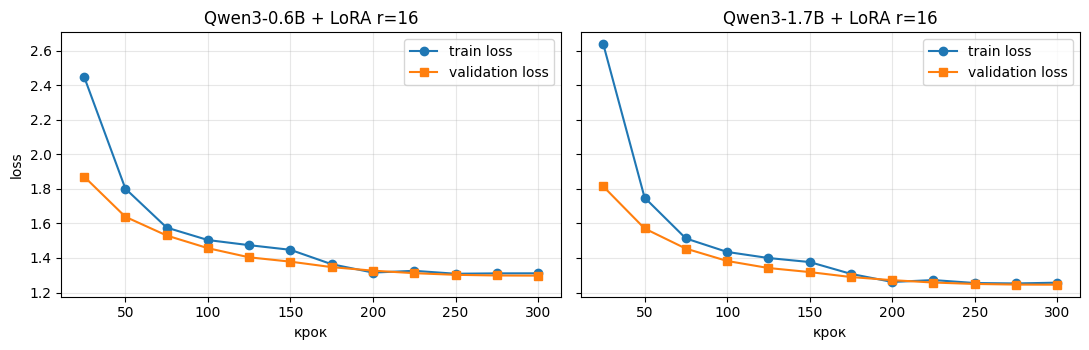

q06-r16: мінімум validation loss на кроці 300 з 300; validation loss не зростає до кінця тренування: перенавчання немає
q17-r16: мінімум validation loss на кроці 300 з 300; validation loss не зростає до кінця тренування: перенавчання немає


In [16]:
# Криві loss: train і validation за кроками
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, key, title in [(axes[0], "q06", "Qwen3-0.6B + LoRA r=16"), (axes[1], "q17", "Qwen3-1.7B + LoRA r=16")]:
    h = exp[key]["history"]
    ax.plot(h.loc[h["loss"].notna(), "step"], h.loc[h["loss"].notna(), "loss"], "o-", label="train loss")
    ax.plot(h.loc[h["eval_loss"].notna(), "step"], h.loc[h["eval_loss"].notna(), "eval_loss"], "s-", label="validation loss")
    ax.set_title(title); ax.set_xlabel("крок"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout(); plt.show()

for key in ["q06", "q17"]:
    ev = exp[key]["history"].dropna(subset=["eval_loss"])
    best_step = int(ev.loc[ev["eval_loss"].idxmin(), "step"])
    last_step = int(ev["step"].max())
    note = ("⚠️ validation loss мінімальний раніше, ніж на останньому кроці: ознака перенавчання" if best_step < last_step
            else "validation loss не зростає до кінця тренування: перенавчання немає")
    print(f"{exp[key]['tag']}: мінімум validation loss на кроці {best_step} з {last_step}; {note}")

In [17]:
# ===== Абляція рангу LoRA на Qwen3-0.6B: r = 4 і 64 (alpha = 2r); r = 16 уже є вище =====
if RUN_RANK_ABLATION:
    for r in (4, 64):
        exp[f"q06_r{r}"] = run_experiment("Qwen/Qwen3-0.6B", f"q06-r{r}", r=r, before=False, general=False)
    abl = pd.DataFrame({f"r={e['r']}": {**e["stats"], "Усі вимоги, %": e["after"]["Усі вимоги разом, %"],
                                        "Всі такти правильної довжини, %": e["after"]["Всі такти правильної довжини, %"]}
                        for e in [exp["q06_r4"], exp["q06"], exp["q06_r64"]]}).T
    display(abl.round(3))
else:
    print("Абляцію пропущено (RUN_RANK_ABLATION = False)")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/150 [00:00<?, ? examples/s]

... (15 outputs left out)

trainable params: 40,370,176 || all params: 636,420,096 || trainable%: 6.3433


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,2.227357,1.696106,1.762440,0.626182,39475.000000
50,1.660911,1.522192,1.502961,0.650842,78999.000000
75,1.473097,1.425015,1.400110,0.666409,117334.000000
100,1.410905,1.371639,1.365635,0.674655,157856.000000
125,1.382383,1.314499,1.201540,0.688301,197990.000000
150,1.357734,1.289684,1.331212,0.688959,237054.000000
175,1.283626,1.260352,1.228091,0.695266,276840.000000
200,1.234447,1.236619,1.254224,0.700507,316483.000000
225,1.236935,1.221426,1.207149,0.702915,353839.000000
250,1.217244,1.209717,1.210942,0.704125,393163.000000


[q06-r64] після донавчання: усі вимоги 11.0 %, парситься 84.5 %


,"Тривалість, хв","Пікова памʼять GPU, GB",Validation loss,"Параметрів LoRA, млн","Усі вимоги, %","Всі такти правильної довжини, %"
r=4,7.296,1.572,1.415,2.523,8.5,37.0
r=16,7.650,1.694,1.298,10.093,7.0,40.0
r=64,7.578,2.182,1.204,40.370,11.0,46.5


## 1.5. Порівняння до і після донавчання

Усі конфігурації оцінено на **одних і тих самих тестових запитах** одним способом генерації. «До» = довгий промпт, «після» = короткий.

,"Чиста відповідь, %","Парситься, %","Всі такти правильної довжини, %","Заголовок збігається, %","Кількість тактів збігається, %","Усі вимоги разом, %","±95 % CI (усі вимоги), п.п.",Середня |Δ тактів|,Частка унікальних тактів,"Дослівні копії train, %"
Еталонні мелодії теста (верхня межа),100.0,100.0,100.0,100.0,100.0,100.0,0.00,0.00,0.77,0.0
"Qwen3-0.6B, до (довгий промпт)",100.0,100.0,56.0,71.0,4.0,0.0,0.00,19.82,0.38,35.0
"Qwen3-0.6B + LoRA r=16, після",100.0,76.5,40.0,100.0,16.5,7.0,3.54,5.02,0.27,0.0
"Qwen3-1.7B, до (довгий промпт)",100.0,94.5,13.5,92.5,56.0,5.5,3.16,11.41,0.23,6.0
"Qwen3-1.7B + LoRA r=16, після",100.0,82.5,34.0,100.0,32.5,10.5,4.25,2.99,0.30,0.0
"Qwen3-0.6B + LoRA r=4, після",100.0,76.0,37.0,100.0,21.5,8.5,3.87,5.06,0.23,0.0
"Qwen3-0.6B + LoRA r=64, після",100.0,84.5,46.5,100.0,24.0,11.0,4.34,3.92,0.30,0.0


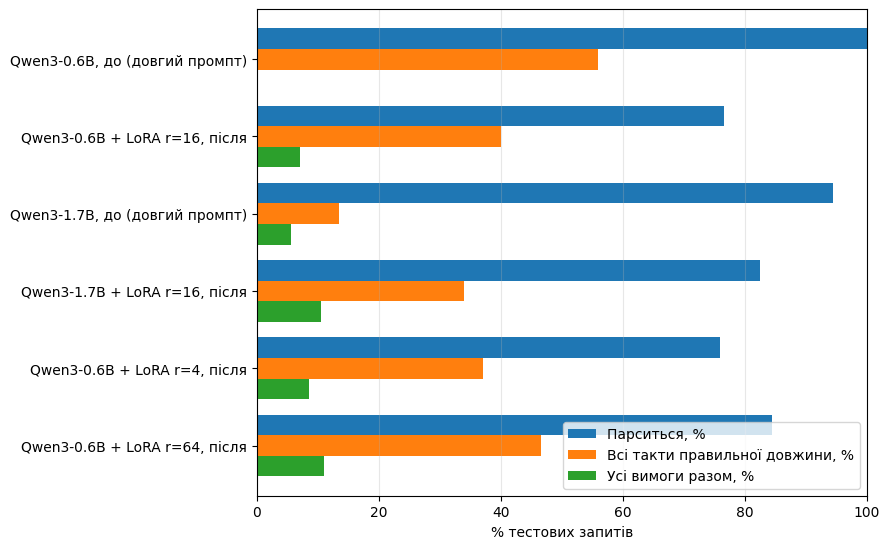

,Qwen3-0.6B,Qwen3-1.7B
Токенів у системному промпті «до» / «після»,383 / 12,383 / 12
"Тренування, хв",7.65024,12.077498
"Пікова памʼять GPU, GB",1.694007,4.317888
"Параметрів LoRA, млн",10.092544,17.432576
"Генерація, с/мелодію «до» → «після»",1.42 → 1.46,1.87 → 1.50


In [18]:
NAMES = {
    "Еталонні мелодії теста (верхня межа)": gold,
    "Qwen3-0.6B, до (довгий промпт)": exp["q06"]["before"],
    "Qwen3-0.6B + LoRA r=16, після": exp["q06"]["after"],
    "Qwen3-1.7B, до (довгий промпт)": exp["q17"]["before"],
    "Qwen3-1.7B + LoRA r=16, після": exp["q17"]["after"],
}
if RUN_RANK_ABLATION:
    NAMES["Qwen3-0.6B + LoRA r=4, після"] = exp["q06_r4"]["after"]
    NAMES["Qwen3-0.6B + LoRA r=64, після"] = exp["q06_r64"]["after"]
results_df = pd.DataFrame(NAMES).T
display(results_df.round(2))

main_cols = ["Парситься, %", "Всі такти правильної довжини, %", "Усі вимоги разом, %"]
plot_df = results_df.drop(index="Еталонні мелодії теста (верхня межа)")[main_cols]
ax = plot_df.plot.barh(figsize=(9, 0.6 * len(plot_df) + 2), width=0.8)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% тестових запитів"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

cost = pd.DataFrame({
    "Qwen3-0.6B": {"Токенів у системному промпті «до» / «після»": f"{n_long} / {n_short}",
                   "Тренування, хв": exp["q06"]["stats"]["Тривалість, хв"], "Пікова памʼять GPU, GB": exp["q06"]["stats"]["Пікова памʼять GPU, GB"],
                   "Параметрів LoRA, млн": exp["q06"]["stats"]["Параметрів LoRA, млн"],
                   "Генерація, с/мелодію «до» → «після»": f"{exp['q06']['before_sec_per_tune']:.2f} → {exp['q06']['after_sec_per_tune']:.2f}"},
    "Qwen3-1.7B": {"Токенів у системному промпті «до» / «після»": f"{n_long} / {n_short}",
                   "Тренування, хв": exp["q17"]["stats"]["Тривалість, хв"], "Пікова памʼять GPU, GB": exp["q17"]["stats"]["Пікова памʼять GPU, GB"],
                   "Параметрів LoRA, млн": exp["q17"]["stats"]["Параметрів LoRA, млн"],
                   "Генерація, с/мелодію «до» → «після»": f"{exp['q17']['before_sec_per_tune']:.2f} → {exp['q17']['after_sec_per_tune']:.2f}"},
})
display(cost)

In [19]:
# Ті самі 3 запити: що відповідала модель до і після (Qwen3-1.7B)
for i in range(3):
    b, a = exp["q17"]["before_df"].iloc[i], exp["q17"]["after_df"].iloc[i]
    print("=" * 78)
    print("ЗАПИТ:\n" + b["prompt"])
    print(f"\n--- ДО (довгий промпт): усі вимоги = {b['all_ok']}; парситься = {b['parse_ok']}; діагностика: {b['log'][:2]}")
    print(b["answer"][:600])
    print(f"\n--- ПІСЛЯ (LoRA, короткий промпт): усі вимоги = {a['all_ok']}; парситься = {a['parse_ok']}; діагностика: {a['log'][:2]}")
    print(a["answer"][:600])

ЗАПИТ:
Meter: 6/8
Key: D major
Unit note length: 1/8
Number of bars: 18

--- ДО (довгий промпт): усі вимоги = False; парситься = True; діагностика: []
X:1
L:1/8
M:6/8
K:D
CDEFGA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA |]

--- ПІСЛЯ (LoRA, короткий промпт): усі вимоги = False; парситься = True; діагностика: []
X:1
L:1/8
M:6/8
K:D
B | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 z |
d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 z | d2 B A2 d | c2 A A2 |]
ЗАПИТ:
Meter: 2/2
Key: C major
Unit note length: 1/4
Number of bars: 12

--- ДО (довгий промпт): усі вимоги = True; парситься = True; діагностика: []
X:1
L:1/4
M:2/2
K:C
CDEFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA | GFGA |]

--- ПІСЛЯ (LoRA, короткий промпт): усі вимоги = False; парситься = True; діагностика: ['Warnin

### Аналіз помилок

Дивимось на **типи** помилок, чи залежить успіх від розміру й кількості тактів, у який бік помиляється довжина і як виглядають найгірші відповіді.

In [20]:
def kinds_table(df, top=6):
    c = Counter(k for ks in df["kinds"] for k in ks)
    return pd.Series(c).sort_values(ascending=False).head(top)

for key, title in [("q17", "Qwen3-1.7B"), ("q06", "Qwen3-0.6B")]:
    print(f"\n##### {title}: найчастіші причини невалідності #####")
    display(pd.DataFrame({"до": kinds_table(exp[key]["before_df"]), "після": kinds_table(exp[key]["after_df"])}).fillna(0).astype(int))

after = exp["q17"]["after_df"].copy()
after["такти запитано"] = pd.cut(after["bars_req"], [0, 12, 16, 24, 32], labels=["8–12", "13–16", "17–24", "25–32"])

def rate(by):
    g = after.groupby(by, observed=True).agg(n=("all_ok", "size"), всі_вимоги=("all_ok", "mean"), такти_збіг=("bars_exact", "mean"),
                                             сер_Δ_тактів=("bar_diff", "mean"))
    g[["всі_вимоги", "такти_збіг"]] = (100 * g[["всі_вимоги", "такти_збіг"]]).round(1)
    return g.round(2)

print("\n##### Qwen3-1.7B після: успіх за розміром (meter) #####")
display(rate("meter").sort_values("n", ascending=False).head(6))
print("##### … за кількістю запитаних тактів #####")
display(rate("такти запитано"))

print("\n##### Найгірші відповіді Qwen3-1.7B після донавчання #####")
for _, row in after[~after["all_ok"]].head(3).iterrows():
    print(f"ЗАПИТ: {row['prompt'].replace(chr(10), ' | ')}")
    print(f"запитано тактів: {row['bars_req']}, згенеровано: {row['bars_gen']}; діагностика: {row['log'][:2]}")
    print(row["answer"][:350] + "\n" + "-" * 70)


##### Qwen3-1.7B: найчастіші причини невалідності #####


,до,після
Missing :| at end of tune,0,40
Unknown mode 'Ador',1,0
Unrecognized character,238,0
"Unrecognized chord name ""dor""",0,1
"Unrecognized chord name ""min""",0,49
found another |: after a |:,0,1
Такти неправильної довжини,162,97



##### Qwen3-0.6B: найчастіші причини невалідності #####


,до,після
Missing :| at end of tune,0,49
"Unrecognized chord name ""min""",0,22
Такти неправильної довжини,88,73



##### Qwen3-1.7B після: успіх за розміром (meter) #####


,n,всі_вимоги,такти_збіг,сер_Δ_тактів
meter,,,,
4/4,75,9.3,24.0,0.57
6/8,43,18.6,30.2,1.33
2/2,33,12.1,33.3,3.33
3/4,22,4.5,54.5,0.14
2/4,20,5.0,40.0,0.90
9/8,4,0.0,25.0,2.25


##### … за кількістю запитаних тактів #####


,n,всі_вимоги,такти_збіг,сер_Δ_тактів
такти запитано,,,,
8–12,31,16.1,38.7,1.81
13–16,45,15.6,37.8,1.29
17–24,101,8.9,34.7,0.03
25–32,23,0.0,4.3,5.52



##### Найгірші відповіді Qwen3-1.7B після донавчання #####
ЗАПИТ: Meter: 6/8 | Key: D major | Unit note length: 1/8 | Number of bars: 18
запитано тактів: 18, згенеровано: 17; діагностика: []
X:1
L:1/8
M:6/8
K:D
B | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 z |
d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 c | d2 B A2 d | c2 A A2 z | d2 B A2 d | c2 A A2 |]
----------------------------------------------------------------------
ЗАПИТ: Meter: 2/2 | Key: C major | Unit note length: 1/4 | Number of bars: 12
запитано тактів: 12, згенеровано: 18; діагностика: ['Warning in line-char 5-14 : Track 0 Bar 1 has 3 time units while the time signature has 2', 'Warning in line-char 5-25 : Track 0 Bar 2 has 3 time units while the time signature has 2']
X:1
L:1/4
M:2/2
K:C
c2 | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB || c2 |
cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB | cB cB cB |

### Чи не втратила модель загальних здібностей?

8 запитів поза нашою задачею плюс один *вільний* музичний запит, якого в тренуванні не було. Жадібна генерація, без системного промпту. Порівнюємо **вихідну модель** і **донавчену**.

In [21]:
for key, title in [("q06", "Qwen3-0.6B"), ("q17", "Qwen3-1.7B")]:
    g = exp[key]["general"]
    print(f"\n##### {title}: пройдено перевірок: вихідна {int(g['вихідна ✓'].sum())}/{len(g)}, донавчена {int(g['донавчена ✓'].sum())}/{len(g)} #####")
    show = g.copy()
    for c in ["вихідна модель", "донавчена"]:
        show[c] = show[c].str.replace("\n", " ⏎ ").str.slice(0, 110)
    display(show)


##### Qwen3-0.6B: пройдено перевірок: вихідна 6/8, донавчена 6/8 #####


,запит,вихідна модель,донавчена,вихідна ✓,донавчена ✓
0,Яка столиця Франції? Відповідай одним словом.,Франція.,A:1 ⏎ L:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ F:1 ⏎ ...,False,False
1,Скільки буде 17 * 3 + 4? Дай лише число.,17 * 3 + 4 = 51 + 4 = **55**.,17 * 3 + 4 = 51 + 4 = 55,True,True
2,Write a Python function is_palindrome(s) that returns True if s is a palindrome.,Here's a Python function `is_palindrome(s)` that checks whether a string `s` is a palindrome: ⏎ ...,X:1 ⏎ L:1 ⏎ def is_palindrome(s): ⏎ return s == s[::-1],True,True
3,"Translate to English: «Доброго ранку, як справи?»","""Good morning, how are you?""","""Good morning, what is your name?""",True,True
4,"Поясни одним реченням, що таке тональність у музиці.","Тональність у музиці — це відповідність зміні звуку, звуковому зміні та звуковому рівнім вибору ...",Тональність у музиці — це відповідність змісту та звукових змін до таємних (трансформаційних) зм...,True,True
5,What is a time signature? Answer in two sentences.,A time signature indicates the number of beats per measure and the duration of each beat. It tel...,"A time signature is a notation system used to indicate the rhythm of a musical piece, specifying...",True,True
6,Напиши коротке вітання з днем народження.,"Звітівівіння з днем народження: ⏎ ⏎ Звітівівіння з днем народження — це діяча, яка підтримує ...","Дорогий друг, відкривши двері, як і ти, відомий і звідиною, відомий і звідиною, відомий і звідин...",True,True
7,Write a short lively jig in D major in ABC notation.,"**Jig: ""Sunshine on the Beach""** ⏎ **Key: D Major** ⏎ **Notation: ABC** ⏎ ⏎ **[Lead Song:...","X:1 ⏎ L:1 ⏎ D |""D"" A2 A A2 A |""G"" G2 G G2 G |""D"" A2 A A2 A |""D"" G2 G G2 D |""D"" A2 A A2 A |""G"" G2...",False,False



##### Qwen3-1.7B: пройдено перевірок: вихідна 7/8, донавчена 7/8 #####


,запит,вихідна модель,донавчена,вихідна ✓,донавчена ✓
0,Яка столиця Франції? Відповідай одним словом.,Париж,1. **Париж**,True,True
1,Скільки буде 17 * 3 + 4? Дай лише число.,17 * 3 + 4 = 51 + 4 = **55**,17 * 3 + 4 = 51 + 4 = 55,True,True
2,Write a Python function is_palindrome(s) that returns True if s is a palindrome.,Sure! Here's a Python function `is_palindrome(s)` that checks whether a string `s` is a palindro...,1 ⏎ def is_palindrome(s): ⏎ return s == s[::-1],True,True
3,"Translate to English: «Доброго ранку, як справи?»","""Good morning, how are things going?""","1. Good morning, how are things? ⏎ 2. Good morning, how are you?",True,True
4,"Поясни одним реченням, що таке тональність у музиці.","Тональність у музиці — це система звукових тонів, які відповідають певному тоновому рівню і стру...","1. Тональність у музиці — це система звукових інтенсів, які визначають характер і рівень відхиле...",True,True
5,What is a time signature? Answer in two sentences.,"A time signature is a symbol used in music to indicate the rhythmic structure of a piece, showin...",1. A time signature is a symbol used in music to indicate the meter and time signature of a piec...,True,True
6,Напиши коротке вітання з днем народження.,"Доброго дня! 🎉 ⏎ С днем народження! Успіхів, радості, здравства і безпеки!","**Вітання з днем народження!** 🎉 ⏎ Сподівається, що ти зустрівся з добрим настроєм, добрим розум...",True,True
7,Write a short lively jig in D major in ABC notation.,"Sure! Here's a short, lively jig in **D major** in **ABC notation**. It's playful, upbeat, and f...",X:1 ⏎ L:1/2 |: A | B2 A2 B2 A2 | B2 A2 B2 A2 | B2 A2 B2 A2 | B2 A2 B2 A2 | B2 A2 B2 A2 | B2 A2 B...,False,False


### Прослуховування

Метрики кажуть, що мелодія *правильна*, але не що вона *звучить*. Синтезуємо кілька мелодій у звук. Файли `.abc` і `.mid` кількох зразків зберігаємо в `samples/`.

In [22]:
def synth(abc, name):
    """ABC → MIDI (abc2midi) → WAV (fluidsynth). Повертає шлях до WAV або None."""
    os.makedirs("samples", exist_ok=True)
    abc_path, mid_path, wav_path = (f"samples/{name}.{ext}" for ext in ("abc", "mid", "wav"))
    with open(abc_path, "w", encoding="utf-8") as f:
        f.write(abc + "\n")
    subprocess.run(["abc2midi", abc_path, "-o", mid_path], capture_output=True)
    if not os.path.exists(mid_path):
        return None
    try:
        subprocess.run(["fluidsynth", "-ni", SF2, mid_path, "-F", wav_path, "-r", "16000"], capture_output=True)
    except OSError:      # fluidsynth не встановлено
        return None
    return wav_path if os.path.exists(wav_path) else None


good = exp["q17"]["after_df"]
good_tunes = [extract_abc(a) for a in good.loc[good["all_ok"], "answer"]][:5]
os.makedirs("samples", exist_ok=True)
for i, abc in enumerate(good_tunes):
    with open(f"samples/q17_after_{i}.abc", "w", encoding="utf-8") as f:
        f.write(abc + "\n")
    subprocess.run(["abc2midi", f"samples/q17_after_{i}.abc", "-o", f"samples/q17_after_{i}.mid"], capture_output=True)
print(f"Збережено {len(good_tunes)} валідних мелодій у samples/ (.abc і .mid)")

if LISTEN:
    try:
        subprocess.run(["apt-get", "-qq", "install", "-y", "fluidsynth", "fluid-soundfont-gm"], capture_output=True)
    except OSError:
        pass
    SF2 = "/usr/share/sounds/sf2/FluidR3_GM.sf2"
    before_df = exp["q17"]["before_df"]
    before_pick = before_df[before_df["parse_ok"]].head(1)
    for label, abc in [("ПІСЛЯ донавчання (Qwen3-1.7B + LoRA)", good_tunes[0] if good_tunes else None),
                       ("ДО донавчання (Qwen3-1.7B, довгий промпт; перша мелодія, що парситься)",
                        extract_abc(before_pick["answer"].iloc[0]) if len(before_pick) else None)]:
        if abc is None:
            print(f"{label}: підходящої мелодії немає"); continue
        wav = synth(abc, "listen_" + ("after" if "ПІСЛЯ" in label else "before"))
        print(f"\n{label}\n{abc[:300]}")
        display(Audio(wav) if wav else Markdown("_не вдалося синтезувати звук; вставте ABC в https://abc.rectanglered.com_"))

Збережено 5 валідних мелодій у samples/ (.abc і .mid)

ПІСЛЯ донавчання (Qwen3-1.7B + LoRA)
X:1
L:1/8
M:4/4
K:D
|: D2 E2 D2 A2 | B2 G2 B2 G2 | A2 B2 A2 B2 | c2 B2 c2 A2 | D2 E2 D2 A2 | B2 G2 B2 G2 |
A2 B2 A2 B2 | c2 B2 c2 A2 :|



ДО донавчання (Qwen3-1.7B, довгий промпт; перша мелодія, що парситься)
X:1
L:1/8
M:6/8
K:D
CDEFGA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA | GFGFAA |]


In [23]:
PUSH_TO_HUB = False
HUB_REPO = "ipz234gpyu/qwen3-1.7b-irish-abc-lora"

if PUSH_TO_HUB:
    from huggingface_hub import HfApi, notebook_login
    notebook_login()
    api = HfApi()
    api.create_repo(HUB_REPO, exist_ok=True)
    api.upload_folder(folder_path="adapters/q17-r16", repo_id=HUB_REPO)
    print(f"https://huggingface.co/{HUB_REPO}")

https://huggingface.co/ipz234gpyu/qwen3-1.7b-irish-abc-lora


## 1.6. Висновки

**Метрика й результат до донавчання:**

**Головна метрика — «усі вимоги разом»**. Мелодія зараховується, якщо одночасно:
  - парсер не знаходить помилок, і кожен такт має довжину, що відповідає розміру;
  - `M`, `L` і `K` збігаються із запитом;
  - кількість тактів дорівнює запитаній.

Я обрав її, бо вона відображає реальну вимогу користувача: мелодія має відкритися і відповідати параметрам. Додатково міряю окремі складові, середню |Δ тактів|, частку унікальних тактів і дослівні копії train. Еталонні мелодії тесту проходять усе на 100 %, це верхня межа.

«До» = та сама модель із найкращим довгим промптом. Генерація: sampling `temperature=0.7, top_p=0.8, top_k=20`.

| Модель (до, довгий промпт) | парситься | такти ок | заголовок | к-сть тактів | **усі вимоги** | унік. такти | копії train |
|---|---|---|---|---|---|---|---|
| Qwen3-0.6B | 100 % | 56,0 % | 71,0 % | 4,0 % | **0,0 %** | 0,38 | 35 % |
| Qwen3-1.7B | 94,5 % | 13,5 % | 92,5 % | 56,0 % | **5,5 % (±3,2)** | 0,23 | 6 % |

Високий відсоток «парситься» до донавчання оманливий. Моделі писали тривіальні зациклені мелодії на кшталт `GFGFAA | GFGFAA | …`, які парсер приймає, але частка унікальних тактів лише 0,23–0,38. У 0,6B 35 % відповідей збігаються з мелодією з train, імовірно це копія прикладу з промпту.

**Метод донавчання й гіперпараметри:**
| Параметр | Значення | Чому |
|---|---|---|
| LoRA `r` / `alpha` | 16 / 32 | ABC — нова «мова», тому потрібна більша місткість, ніж для простого форматування. `alpha = 2r` тримає масштаб при зміні рангу |
| dropout, `target_modules` | 0,05, `all-linear` | легка регуляризація, адаптери в усіх лінійних шарах |
| `learning_rate`, розклад | 2e-4, cosine, прогрів 10 кроків | типовий lr для LoRA |
| `max_steps` × батч | 300 × (4·2) = 2 400 прикладів | менше однієї епохи по 4 000 мелодій |
| `max_length` | 512 | запит ≈ 90 токенів + мелодія ≤ 380 |
| `fp16` + gradient checkpointing | так | T4 не підтримує bf16, checkpointing економить памʼять |

| | Qwen3-0.6B | Qwen3-1.7B |
|---|---|---|
| Параметрів LoRA | 10,1 млн (1,67 %) | 17,4 млн (1,00 %) |
| Тривалість | 7,65 хв | 12,08 хв |
| Пікова памʼять GPU | 1,69 GB | 4,32 GB |
| Train loss (крок 25 → 300) | 2,449 → 1,311 | 2,637 → 1,257 |
| Validation loss (крок 25 → 300) | 1,871 → 1,298 | 1,814 → 1,245 |
| Mean token accuracy (val) | 0,690 | 0,698 |

**Перенавчання немає.** Validation loss мінімальний на останньому кроці в обох моделей, а різниця train і val loss близько 0,01. Тому гіперпараметри не змінювалися. Крива вже виходить на плато, бо lr спадає за cosine, але loss ще трохи падає, тож модель, імовірно, недотренована.

**Абляція рангу LoRA (Qwen3-0.6B, `alpha = 2r`):**

| r | параметрів LoRA | памʼять | val loss | такти ок | усі вимоги |
|---|---|---|---|---|---|
| 4 | 2,5 млн | 1,57 GB | 1,415 | 37,0 % | 8,5 % |
| 16 | 10,1 млн | 1,69 GB | 1,298 | 40,0 % | 7,0 % |
| 64 | 40,4 млн | 2,18 GB | 1,204 | 46,5 % | 11,0 % |

**Результат після донавчання:**

Той самий тестовий набір, але **короткий** промпт `Compose a tune in ABC notation.`

| Конфігурація | парситься | такти ок | заголовок | к-сть тактів | **усі вимоги** | сер. \|Δ тактів\| | унік. такти | копії |
|---|---|---|---|---|---|---|---|---|
| 0.6B, до | 100 % | 56,0 % | 71,0 % | 4,0 % | 0,0 % | 19,82 | 0,38 | 35 % |
| 0.6B + LoRA r=16 | 76,5 % | 40,0 % | **100 %** | 16,5 % | 7,0 % (±3,5) | 5,02 | 0,27 | 0 % |
| 1.7B, до | 94,5 % | 13,5 % | 92,5 % | 56,0 % | 5,5 % (±3,2) | 11,41 | 0,23 | 6 % |
| **1.7B + LoRA r=16** | 82,5 % | **34,0 %** | **100 %** | 32,5 % | **10,5 % (±4,3)** | **2,99** | 0,30 | 0 % |
| 0.6B + LoRA r=4 | 76,0 % | 37,0 % | 100 % | 21,5 % | 8,5 % | 5,06 | 0,23 | 0 % |
| 0.6B + LoRA r=64 | 84,5 % | 46,5 % | 100 % | 24,0 % | 11,0 % | 3,92 | 0,30 | 0 % |

Що однозначно покращилося:
  - Збіг заголовка `M`, `L`, `K` зріс до 100 % у всіх конфігураціях.
  - У 1.7B частка тактів правильної довжини зросла з 13,5 % до 34,0 %.
  - Середня похибка кількості тактів зменшилась у 3,8 раза для 1.7B і в 3,9 раза для 0.6B.
  - Зникли дослівні копії train.

Що не покращилося або погіршилося:
  - Частка «парситься» впала з 94,5 % до 82,5 % у 1.7B і зі 100 % до 76,5 % у 0.6B.
  - У 0.6B частка тактів правильної довжини знизилась з 56 % до 40 %, але «до» це були тривіальні зациклені мелодії.
  - Точний збіг кількості тактів у 1.7B впав із 56 % до 32,5 %, бо «до» модель механічно повторювала один шаблон.
  - Головна метрика майже подвоїлась 5,5 → 10,5 %, але 95 % довірчі інтервали частково перекриваються, тож по цій метриці покращення на межі статистичної значущості.
  - Усі мелодії зі всіма виконаними вимогами складають лише ~10 %, тобто практично модель ще не придатна для використання.

Інше:
  - Швидкість генерації не змінилась.
  - Абляція показує монотонне покращення validation loss і частки правильних тактів із ростом `r`. Метрика «усі вимоги» шумна. Цікаво, що 0.6B з `r=64` (11,0 %) на рівні 1.7B з `r=16` (10,5 %), хоча й за вищої памʼяті на адаптер.
  - Три приклади відповідей до і після для 1.7B наведено в блокноті.

**Аналіз помилок:**

**Типи помилок (1.7B).**
  - До донавчання: 238 випадків `Unrecognized character` модель писала не ABC, а довільні символи, 162 мелодії з тактами неправильної довжини.
  - Після: `Unrecognized character` зникли, тактів неправильної довжини 97. З'явилися два нові типи: `Missing :| at end of tune` і `Unrecognized chord name "min"` - 49 випадків, ймовірно модель вигадує назви акордів у лапках, яких парсер не знає. У 0.6B аналогічно: 49 і 22 випадки. Обидва типи технічні і легко виправляються: допис `:|`, заборона акордів у даних, більше кроків.

**Арифметика тривалостей — головна проблема.** Модель не рахує тривалості, а імітує вигляд тактів. У прикладах з блокнота вона пише один такт неправильної довжини і повторює його в усіх тактах. Тому 100 % збігу заголовка співіснує з лише 34 % правильних тактів.

**Залежність від кількості тактів (1.7B, n = 200).**
  - 8–12 тактів: 16,1 % успіху; 13–16: 15,6 %; 17–24: 8,9 %; **25–32: 0 %** (n = 23).
  - Для довгих мелодій модель «зривається»: на запит 27 тактів згенерувала 49 (середня Δ +5,5). Мелодія повторюється циклами аж до ліміту `max_new_tokens`. Частина причини, ймовірно, в тому, що тренувальні мелодії обмежені ≤ 380 токенів, тож довгі зразки в train майже відсутні.

**Залежність від розміру** малі вибірки, n = 4–75, висновки обережні: найкраще 6/8 (18,6 %), 4/4 дає 9,3 %, 3/4 лише 4,5 %, хоча кількість тактів там влучає найчастіше (54,5 %), 9/8 дає 0 % (n = 4).

**Зациклення.** Частка унікальних тактів 0,27–0,30 проти 0,77 в еталонів. Модель надмірно повторює такти, мелодії одноманітні. Копій train немає, тож це не запамʼятовування, а колапс до простих патернів.

**Загальні здібності - 8 запитів, жадібна генерація, адаптер вимкнено/увімкнено.**
  - Автоматичні перевірки: 6/8 → 6/8 для 0.6B, 7/8 → 7/8 для 1.7B, формально без змін.
  - Але вручну видно побічні ефекти. У 0.6B ABC-формат «просочується» в чужі відповіді: на питання про столицю Франції донавчена модель видає `A:1 L:1 F:1 F:1…`, перед кодом Python з'являється `X:1 L:1`. У 1.7B ефект м'якший: зʼявилась нумерація «1.» перед відповідями.
  - Вільний запит «напиши джигу в D major в ABC» обидві донавчені моделі проходять погано: у видимому фрагменті відповіді немає рядка `K:`, а `L:1/2` і `L:1` нетипові. Тобто модель вивчила саме наш шаблон запиту, а не загальне вміння писати ABC.
  - Вихідна 0.6B і без донавчання відповідає погано, тож частину деградації на українській не можна віднести на рахунок LoRA.

**Висновок:**

  **Гіпотези з розділу 1.1:**
  1. *Довгий промпт дає валідні мелодії рідко, після SFT частка зростає в рази* — **частково підтверджена**. Головна метрика: 0 → 7 % (0.6B) і 5,5 → 10,5 % (1.7B). Але в абсолютних числах це мало, довірчі інтервали перекриваються, а парсабельність знизилась. Реальний виграш у структурних метриках: заголовок 100 %, правильні такти у 2,5 раза частіші (1.7B), похибка кількості тактів у ~4 рази менша.
  2. *Числові обмеження виконати важче, ніж писати синтаксично коректний ABC* — **підтверджена в абсолютних числах**: парситься 82,5 %, правильні такти 34 %, кількість тактів 32,5 %, усе разом 10,5 %. Проте «зросте менше» не підтвердилося: синтаксис не покращився, а числові метрики зросли.
  3. *Більша модель краща, після донавчання розрив скоротиться* — **частково**. 1.7B краще за 0.6B за більшістю метрик, а розрив у головній метриці скоротився з 5,5 до 3,5 п.п. Але це в межах похибки, а 0.6B має вищу частку правильних тактів, і 0.6B з `r=64` дорівнює 1.7B з `r=16`.
  4. *LoRA майже не псує загальних здібностей* — **формально підтверджена**, але ручний огляд виявив просочування формату ABC у відповіді 0.6B і стильовий дрейф у 1.7B.

**Чи виправдане донавчання.** Частково. Воно дає стабільну, дешеву вигоду в форматі та економить 97 % токенів системного промпту, але якість лишається низькою: лише ~10 % мелодій повністю відповідають запиту. Для реального використання цього замало.

Адаптер Qwen3-1.7B опубліковано на Hugging Face Hub: https://huggingface.co/ipz234gpyu/qwen3-1.7b-irish-abc-lora